# Learning scikit-learn with your stock database

This notebook teaches sklearn from scratch using the tables in your pipeline database (`price_history` and `fundamentals_snapshot`).

**Roadmap**

1. The estimator API on a toy problem (`fit`, `predict`, `transform`, `score`)
2. Load your data from SQLite
3. Build features and targets from prices
4. Train/test splitting for time series (and why shuffling is wrong here)
5. Regression, with a baseline
6. Classification, with a baseline
7. Pipelines and time-series cross-validation
8. Random forests and feature importance
9. Unsupervised learning on fundamentals (PCA and KMeans)
10. Exercises

A word of warning up front: daily stock returns are very close to noise. Your models will mostly score near the baseline. That is the lesson, not a bug. Learning to tell a real signal from a lucky fit is the most valuable skill in applied ML for finance.

In [1]:
# pip install scikit-learn pandas matplotlib   (run once if needed)
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DB_PATH = "../data/finance.db"  # change to the path of your pipeline database
INTERVAL = "1d"         # must match the interval string stored in price_history

pd.set_option("display.width", 140)
np.random.seed(42)

## 1. The estimator API on a toy problem

Almost everything in sklearn follows one pattern:

- **Estimators** learn from data with `.fit(X, y)`. `X` is a 2D array of shape `(n_samples, n_features)`, `y` is 1D.
- **Predictors** (regressors and classifiers) then offer `.predict(X)` and `.score(X, y)`.
- **Transformers** (scalers, PCA, imputers) offer `.fit(X)` then `.transform(X)`.
- Learned attributes end with an underscore, like `coef_` and `intercept_`.

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(0)
X_toy = rng.uniform(0, 10, size=(200, 1))            # 200 samples, 1 feature
y_toy = 3.0 * X_toy[:, 0] + 5.0 + rng.normal(0, 2, 200)

X_tr, X_te, y_tr, y_te = train_test_split(X_toy, y_toy, test_size=0.25, random_state=0)

model = LinearRegression()
model.fit(X_tr, y_tr)

print("slope:", model.coef_[0], " intercept:", model.intercept_)   # should be near 3 and 5
print("R^2 on test data:", model.score(X_te, y_te))

slope: 2.906079084493278  intercept: 5.299626439968666
R^2 on test data: 0.9496983339917833


`score` for a regressor is R squared: 1.0 is perfect, 0.0 means no better than always predicting the mean of `y`, and negative means worse than that. Keep this number in mind, we will see it near zero on stock data.

Random shuffling in `train_test_split` is fine for this toy problem. It will be **wrong** for prices, as shown in section 4.

## 2. Load your data from SQLite

In [4]:
def load_prices(conn, interval="1d", source=None):
    """Load OHLCV price history from the database.

    Parameters
    ----------
    conn : sqlite3.Connection
        Open connection to the pipeline database.
    interval : str, default "1d"
        Value of the ``interval`` column to select.
    source : str or None, default None
        If given, only rows from this data source are returned.

    Returns
    -------
    pandas.DataFrame
        Columns ticker, source, datetime, Open, High, Low, Close, Volume,
        with ``datetime`` parsed as timezone-aware UTC timestamps.
    """
    query = (
        "SELECT ticker, source, datetime, Open, High, Low, Close, Volume "
        "FROM price_history WHERE interval = ?"
    )
    params = [interval]
    if source is not None:
        query += " AND source = ?"
        params.append(source)
    df = pd.read_sql_query(query, conn, params=params)
    df["datetime"] = pd.to_datetime(df["datetime"], utc=True)
    return df


def load_latest_fundamentals(conn):
    """Load the most recent fundamentals snapshot for each ticker.

    Parameters
    ----------
    conn : sqlite3.Connection
        Open connection to the pipeline database.

    Returns
    -------
    pandas.DataFrame
        One row per ticker, taken from the latest ``fetched_at`` value.
    """
    query = """
        SELECT f.*
        FROM fundamentals_snapshot f
        JOIN (
            SELECT ticker, MAX(fetched_at) AS max_fetched
            FROM fundamentals_snapshot
            GROUP BY ticker
        ) m ON f.ticker = m.ticker AND f.fetched_at = m.max_fetched
    """
    return pd.read_sql_query(query, conn)


conn = sqlite3.connect(DB_PATH)
prices = load_prices(conn, interval=INTERVAL)
print(prices.shape)
print(prices.groupby(["ticker", "source"]).size().head(10))
prices.head()

(2954808, 8)
ticker  source  
A       yfinance    6738
AAPL    yfinance    6738
ABBV    yfinance    3469
ABNB    yfinance    1469
ABT     yfinance    6738
ACGL    yfinance    6738
ACN     yfinance    6349
ADBE    yfinance    6738
ADI     yfinance    6738
ADM     yfinance    6738
dtype: int64


,ticker,source,datetime,Open,High,Low,Close,Volume
0,PSKY,yfinance,2005-12-05 00:00:00+00:00,18.714360,18.714360,16.655781,16.655781,1087800
1,PSKY,yfinance,2005-12-06 00:00:00+00:00,16.749352,16.749352,16.063159,16.069397,1743800
2,PSKY,yfinance,2005-12-07 00:00:00+00:00,16.219118,16.219118,15.751259,15.938402,1536400
3,PSKY,yfinance,2005-12-08 00:00:00+00:00,15.925917,16.063156,15.657678,15.838583,2100700
4,PSKY,yfinance,2005-12-09 00:00:00+00:00,15.844818,16.187915,15.564104,15.988295,2414700


If a ticker appears under more than one `source`, you would be double counting it. Pick one source before continuing:

In [5]:
# Keep one source per ticker (the one with the most rows). Adjust if you prefer a specific source.
counts = prices.groupby(["ticker", "source"]).size().rename("n").reset_index()
best = counts.sort_values("n", ascending=False).drop_duplicates("ticker")[["ticker", "source"]]
prices = prices.merge(best, on=["ticker", "source"]).drop(columns="source")
print(prices["ticker"].nunique(), "tickers,", len(prices), "rows")

503 tickers, 2954808 rows


## 3. Features and targets

Supervised learning needs a feature matrix `X` and a target `y`. Here the question is: **using only information available at today's close, can we predict tomorrow's return?**

Two targets from the same features:

- `target_ret`: tomorrow's return (regression)
- `target_up`: 1 if tomorrow's return is positive, else 0 (classification)

The `.shift(-1)` is where the future enters, and it must only ever be used for the target, never for a feature.

In [6]:
FEATURES = ["ret_1d", "ret_5d", "ret_20d", "vol_20d", "range_pct", "volume_chg"]


def make_features(df):
    """Build return, volatility and volume features for a single ticker.

    Parameters
    ----------
    df : pandas.DataFrame
        Price history for one ticker with columns datetime, High, Low,
        Close and Volume.

    Returns
    -------
    pandas.DataFrame
        Input sorted by datetime with the feature columns in ``FEATURES``
        plus ``target_ret`` (next-period return) and ``target_up``
        (1 if the next-period return is positive). Rows with missing
        values are dropped.
    """
    df = df.sort_values("datetime").copy()
    df["ret_1d"] = df["Close"].pct_change()
    df["ret_5d"] = df["Close"].pct_change(5)
    df["ret_20d"] = df["Close"].pct_change(20)
    df["vol_20d"] = df["ret_1d"].rolling(20).std()
    df["range_pct"] = (df["High"] - df["Low"]) / df["Close"]
    df["volume_chg"] = df["Volume"].pct_change().replace([np.inf, -np.inf], np.nan)
    df["target_ret"] = df["ret_1d"].shift(-1)
    df["target_up"] = (df["target_ret"] > 0).astype(int)
    return df.dropna(subset=FEATURES + ["target_ret"])


# Build features one ticker at a time so rolling windows never cross tickers
data = (
    pd.concat([make_features(g) for _, g in prices.groupby("ticker")])
    .sort_values("datetime")
    .reset_index(drop=True)
)
print(data.shape)
data[["ticker", "datetime"] + FEATURES + ["target_ret", "target_up"]].tail()

(2937828, 15)


,ticker,datetime,ret_1d,ret_5d,ret_20d,vol_20d,range_pct,volume_chg,target_ret,target_up
2937823,WMB,2026-10-16 00:00:00+00:00,0.029760,-0.019128,-0.010687,0.018543,0.031285,-0.176315,-0.012626,0
2937824,SWK,2026-10-16 00:00:00+00:00,-0.002911,0.044146,0.032373,0.017120,0.035683,0.241215,-0.013949,0
2937825,TROW,2026-10-16 00:00:00+00:00,-0.003946,-0.039844,-0.030626,0.011335,0.025552,-0.198483,-0.008616,0
2937826,TXN,2026-10-16 00:00:00+00:00,-0.009458,-0.025587,0.036904,0.017064,0.037290,0.159227,-0.001194,0
2937827,ZTS,2026-10-16 00:00:00+00:00,0.012242,0.061088,0.111765,0.016670,0.028974,0.110852,0.002645,1


## 4. Splitting: time order matters

If you shuffle rows, the model trains on days after the ones it is tested on. Neighboring days are highly correlated (overlapping rolling windows), so shuffled test scores look better than they really are. This is **look-ahead leakage**.

The honest approach: train on the past, test on the future.

In [7]:
cutoff = data["datetime"].quantile(0.8)
train = data[data["datetime"] <= cutoff]
test = data[data["datetime"] > cutoff]

X_train, y_train_ret, y_train_up = train[FEATURES], train["target_ret"], train["target_up"]
X_test, y_test_ret, y_test_up = test[FEATURES], test["target_ret"], test["target_up"]

print("train:", train["datetime"].min().date(), "to", train["datetime"].max().date(), len(train))
print("test: ", test["datetime"].min().date(), "to", test["datetime"].max().date(), len(test))

train: 2000-02-01 to 2022-01-31 2350683
test:  2022-02-01 to 2026-10-16 587145


## 5. Regression with a baseline

Always compare against a dumb baseline. `DummyRegressor` predicts the training mean every time. If your model cannot beat it on held-out data, it has learned nothing useful.

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score

baseline = DummyRegressor(strategy="mean").fit(X_train, y_train_ret)
linreg = LinearRegression().fit(X_train, y_train_ret)

for name, m in [("baseline", baseline), ("linear regression", linreg)]:
    pred = m.predict(X_test)
    rmse = mean_squared_error(y_test_ret, pred) ** 0.5
    print(f"{name:18s} test R^2 = {r2_score(y_test_ret, pred):+.4f}   RMSE = {rmse:.5f}")

print()
print(pd.Series(linreg.coef_, index=FEATURES).round(4))

baseline           test R^2 = -0.0000   RMSE = 0.02227
linear regression  test R^2 = +0.0003   RMSE = 0.02227

ret_1d       -0.0176
ret_5d       -0.0102
ret_20d      -0.0008
vol_20d       0.0208
range_pct     0.0158
volume_chg   -0.0000
dtype: float64


Expect an R squared at or slightly below zero. A tiny positive number is usually not significant either. Daily returns are mostly unpredictable from simple price features.

## 6. Classification with a baseline

Now predict direction. `DummyClassifier(strategy="most_frequent")` always guesses the most common class, which is the bar to clear. Stocks go up slightly more often than down, so the baseline accuracy will be a bit above 50 percent.

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train_up)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train_up)

for name, m in [("baseline", dummy), ("logistic regression", logreg)]:
    pred = m.predict(X_test)
    print(f"{name:20s} test accuracy = {accuracy_score(y_test_up, pred):.4f}")

pred = logreg.predict(X_test)
print()
print(confusion_matrix(y_test_up, pred))
print(classification_report(y_test_up, pred, zero_division=0))

baseline             test accuracy = 0.5151
logistic regression  test accuracy = 0.5145

[[ 32556 252161]
 [ 32907 269521]]
              precision    recall  f1-score   support

           0       0.50      0.11      0.19    284717
           1       0.52      0.89      0.65    302428

    accuracy                           0.51    587145
   macro avg       0.51      0.50      0.42    587145
weighted avg       0.51      0.51      0.43    587145



Two new ideas here:

- **StandardScaler** rescales each feature to mean 0 and standard deviation 1. Logistic regression (and many other models) behaves better when features share a scale. Fit the scaler on training data only, which is exactly what a pipeline does for you.
- **Confusion matrix**: rows are true classes, columns are predicted classes. Accuracy alone hides whether the model just predicts "up" every time.

## 7. Pipelines and time-series cross-validation

A single train/test split gives one noisy estimate. `TimeSeriesSplit` makes several splits where each test fold comes after its training fold. Because `data` is sorted by datetime, the folds respect time order.

`cross_val_score` clones the whole pipeline for each fold, so the scaler never sees test data.

In [11]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

tscv = TimeSeriesSplit(n_splits=5)
X_all, y_all = data[FEATURES], data["target_up"]

models = {
    "baseline": DummyClassifier(strategy="most_frequent"),
    "logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}
for name, m in models.items():
    scores = cross_val_score(m, X_all, y_all, cv=tscv, scoring="accuracy")
    print(f"{name:10s} folds={np.round(scores, 3)}  mean={scores.mean():.4f}  std={scores.std():.4f}")

baseline   folds=[0.496 0.52  0.524 0.523 0.519]  mean=0.5164  std=0.0103
logistic   folds=[0.512 0.521 0.523 0.522 0.518]  mean=0.5194  std=0.0038


Compare the spread (`std`) between folds to the gap between models. If the gap is smaller than the spread, you cannot claim one is better.

## 8. Random forests and feature importance

A random forest averages many decision trees. It can capture nonlinear effects and feature interactions, and does not need scaling. It also overfits easily, so we limit `max_depth` and set `min_samples_leaf`.

**Hyperparameters** are settings you choose before training (depth, number of trees). Tuning them on the test set would leak information, which is why we use cross-validation on the training portion.

train accuracy: 0.5206
test accuracy:  0.5148
baseline test:  0.5151


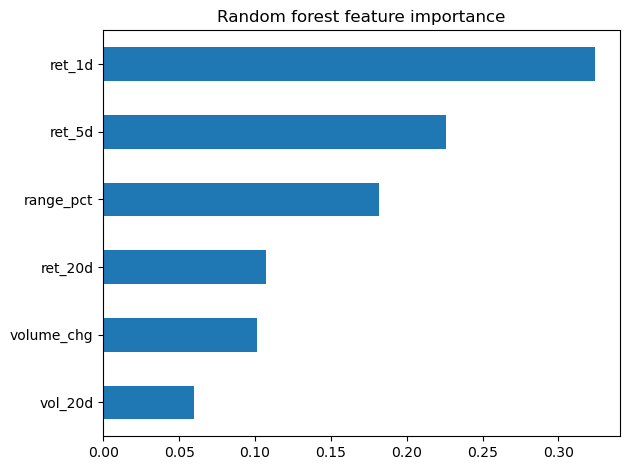

In [12]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200, max_depth=4, min_samples_leaf=50, n_jobs=-1, random_state=42
)
rf.fit(X_train, y_train_up)
print("train accuracy:", round(rf.score(X_train, y_train_up), 4))
print("test accuracy: ", round(rf.score(X_test, y_test_up), 4))
print("baseline test: ", round(dummy.score(X_test, y_test_up), 4))

importances = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
importances.plot.barh(title="Random forest feature importance")
plt.tight_layout()
plt.show()

A large gap between train and test accuracy is **overfitting**: the model memorized noise in the past. Try changing `max_depth` to 12 and watch the train score climb while the test score does not.

In [13]:
from sklearn.model_selection import GridSearchCV

param_grid = {"max_depth": [2, 4, 8], "min_samples_leaf": [20, 50, 100]}
search = GridSearchCV(
    RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
    param_grid,
    cv=TimeSeriesSplit(n_splits=4),
    scoring="accuracy",
)
search.fit(X_train, y_train_up)
print("best params:", search.best_params_)
print("best CV accuracy:", round(search.best_score_, 4))
print("held-out test accuracy:", round(search.score(X_test, y_test_up), 4))

best params: {'max_depth': 4, 'min_samples_leaf': 100}
best CV accuracy: 0.5212
held-out test accuracy: 0.5148


## 9. Unsupervised learning on fundamentals

No target here. We ask: **which companies look alike?**

- `SimpleImputer` fills missing values (common in fundamentals data).
- `StandardScaler` matters even more here, because KMeans and PCA are distance and variance based, and market cap is many orders of magnitude larger than beta.
- `PCA` compresses many features into a few directions of maximum variance, handy for plotting.
- `KMeans` groups points into `k` clusters.

In [14]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score

fund = load_latest_fundamentals(conn).set_index("ticker")
num_cols = ["market_cap", "pe_ratio", "forward_pe", "peg_ratio", "dividend_yield",
            "profit_margin", "debt_to_equity", "beta"]

X_f = fund[num_cols].copy()
X_f["market_cap"] = np.log10(X_f["market_cap"])        # tame the huge scale range
X_f = X_f.dropna(thresh=len(num_cols) // 2)            # drop tickers with mostly missing data

prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
Z = prep.fit_transform(X_f)

for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Z)
    print(f"k={k}  silhouette={silhouette_score(Z, labels):.3f}")

k=2  silhouette=0.242
k=3  silhouette=0.202
k=4  silhouette=0.238
k=5  silhouette=0.265
k=6  silhouette=0.258


variance explained: [0.252 0.172]


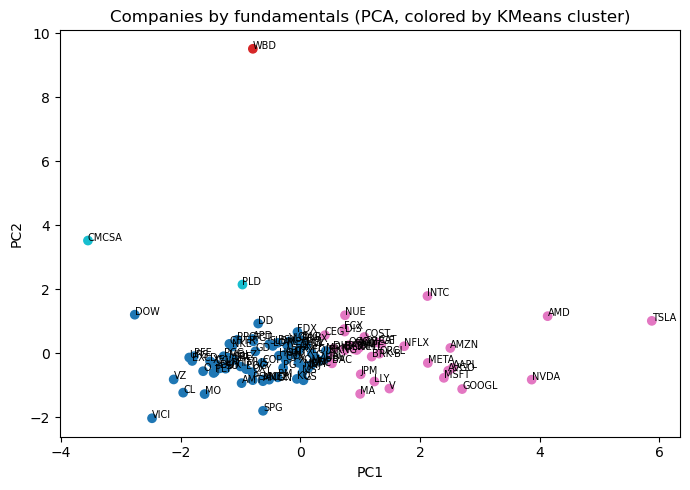

col_0,0,1,2,3
sector,,,,
Basic Materials,8,0,2,0
Communication Services,4,1,4,1
Consumer Cyclical,7,0,3,0
Consumer Defensive,8,0,2,0
Energy,9,0,0,0
Financial Services,4,0,6,0
Healthcare,7,0,3,0
Industrials,7,0,3,0
Real Estate,8,0,1,1


In [15]:
k = 4
km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
pca = PCA(n_components=2).fit(Z)
coords = pca.transform(Z)
print("variance explained:", pca.explained_variance_ratio_.round(3))

plt.figure(figsize=(7, 5))
plt.scatter(coords[:, 0], coords[:, 1], c=km.labels_, cmap="tab10")
for t, (x, y) in zip(X_f.index, coords):
    plt.annotate(t, (x, y), fontsize=7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Companies by fundamentals (PCA, colored by KMeans cluster)")
plt.tight_layout()
plt.show()

# Do clusters line up with sectors?
pd.crosstab(fund.loc[X_f.index, "sector"], km.labels_)

Two things to check: how much variance the first two components capture (low means the 2D plot is a loose picture), and whether clusters roughly match sectors or cut across them. Clusters that cut across sectors can be the interesting finding.

## 10. Exercises

1. Add features (for example `ret_60d`, distance from the 50-day moving average, RSI) to `make_features` and re-run section 7. Does the cross-validated accuracy move more than its fold-to-fold spread?
2. Predict a 5-day-ahead return instead of 1-day. Does predictability change?
3. Replace accuracy with `roc_auc_score` using `predict_proba`. Why is it a better measure than accuracy when classes are imbalanced?
4. Try `GradientBoostingClassifier` and `Ridge` / `Lasso` regression. Compare with the random forest.
5. With the fundamentals table, predict `target_mean / price - 1` (analyst upside) from the other fundamentals, using `train_test_split` with `random_state` and a `Pipeline`. Which features matter?
6. Build a simple backtest: go long when the model predicts "up", flat otherwise. Compare cumulative return to buy and hold. Remember transaction costs.

**Concepts to keep**

- Always fit preprocessing on training data only (use `Pipeline`).
- Always compare against a baseline.
- For time series, split by time, never by shuffling.
- A model that looks good in-sample and bad out-of-sample is overfit.